# Projet de Data Science : Prédiction de la gravité des accidents de la route en France (2005 - 2016)

## 1. Titre et objectif du projet

### Contexte
La sécurité routière demeure un enjeu majeur de santé publique et d'aménagement du territoire en France. Pouvoir anticiper et analyser les facteurs de gravité des accidents corporels permet de guider les politiques de prévention routière et de cibler les aménagements d'infrastructure les plus critiques.

### Objectif Machine Learning
L'objectif de ce projet est de développer un modèle d'apprentissage automatique supervisé (tâche de classification) capable de prédire la gravité d'un accident de la route à partir de ses caractéristiques (conditions atmosphériques, caractéristiques du lieu, profil de la route, types de véhicules impliqués, profils des usagers).

---

## 2. Sources et liens

- **Dataset Kaggle** : [Accidents in France from 2005 to 2016](https://www.kaggle.com/datasets/ahmedlahlou/accidents-in-france-from-2005-to-2016) par Ahmed Lahlou.
- **Source originale** : Base BAAC (Bulletins d'Analyse des Accidents Corporels de la circulation), produite par l'ONISR (Observatoire national interministériel de la sécurité routière) à partir des fiches saisies par les forces de l'ordre.
- **Hébergement du projet** : Les 5 fichiers de données seront hébergés sur le dépôt GitHub du projet [À COMPLÉTER : URL du dépôt].

**Note méthodologique** : Le jeu de données ne recense que les accidents corporels (impliquant au moins une victime). Il n'y a donc aucun accident purement matériel (sans blessé ou tué) documenté dans cette base.

---

## 3. Pourquoi 5 fichiers ?

### Modèle relationnel et granularité
Le jeu de données d'origine est découpé en 5 tables distinctes. Ce choix de modélisation relationnelle évite la redondance massive d'informations. En effet, un accident donné survient en un lieu unique, mais peut impliquer plusieurs véhicules, chacun de ces véhicules transportant plusieurs usagers.

Si l'on construisait une unique table « plate » dès le départ, les informations générales de l'accident et du lieu de la route seraient dupliquées pour chaque usager impliqué, ce qui alourdirait artificiellement le volume de stockage et complexifierait les niveaux d'analyses.

### Rôle de chaque fichier
- **caracteristics.csv** : Décrit les circonstances temporelles, spatiales et lumineuses générales de l'accident.
- **places.csv** : Décrit l'infrastructure routière et la configuration physique de la chaussée au lieu de l'accident.
- **vehicles.csv** : Liste chaque véhicule impliqué dans l'accident.
- **users.csv** : Contient les informations individuelles de chaque usager (conducteur, passager, piéton) ainsi que la variable cible de gravité (`grav`).
- **holidays.csv** : Fournit un calendrier des jours fériés pour la période concernée, permettant d'enrichir l'analyse temporelle.

---

## 4. Dictionnaire des variables

### Table `caracteristics.csv` (1 ligne par accident)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | entier unique | identifiant |
| **jour** | jour du mois | 1 à 31 | numérique |
| **mois** | mois | 1 à 12 | numérique |
| **an** | année | 5 à 16 (2005 à 2016), sur 2 chiffres | numérique |
| **hrmn** | heure et minute au format HHMM | entier de 1 à 2359 (1445 = 14h45) | date/heure |
| **lum** | conditions d'éclairage | 1 plein jour ; 2 crépuscule ou aube ; 3 nuit sans éclairage public ; 4 nuit avec éclairage public non allumé ; 5 nuit avec éclairage public allumé | catégorie codée |
| **agg** | localisation | 1 hors agglomération ; 2 en agglomération | catégorie codée |
| **int** | type d'intersection | 1 hors intersection ; 2 en X ; 3 en T ; 4 en Y ; 5 à plus de 4 branches ; 6 giratoire ; 7 place ; 8 passage à niveau ; 9 autre ; 0 présent dans les données mais non documenté | catégorie codée |
| **atm** | conditions atmosphériques | 1 normale ; 2 pluie légère ; 3 pluie forte ; 4 neige/grêle ; 5 brouillard/fumée ; 6 vent fort/tempête ; 7 temps éblouissant ; 8 temps couvert ; 9 autre | catégorie codée |
| **col** | type de collision | 1 deux véhicules frontale ; 2 deux véhicules par l'arrière ; 3 deux véhicules par le côté ; 4 trois véhicules ou plus en chaîne ; 5 trois véhicules ou plus (collisions multiples) ; 6 autre collision ; 7 sans collision | catégorie codée |
| **com** | commune | numéro INSEE sur 3 chiffres dans le département (0 à 987), unique seulement avec dep | catégorie codée |
| **adr** | adresse postale | texte libre, renseignée surtout en zone urbaine (17 % de valeurs manquantes) | texte |
| **gps** | origine des coordonnées GPS | M métropole ; A Antilles ; G Guyane ; R Réunion ; Y Mayotte (autres valeurs rares non documentées) | catégorie codée |
| **lat** | latitude | valeur en degrés x 10^5 (ex. 4370200 = 43,702°), beaucoup de 0 et de valeurs manquantes (environ 57 %) | numérique |
| **long** | longitude | même codage que lat, lue comme texte, peut être négative | numérique |
| **dep** | département | code INSEE x 10 (590 = Nord, 750 = Paris, 201 = Corse-du-Sud, 202 = Haute-Corse, 971 à 976 = DOM), 101 valeurs distinctes | catégorie codée |

#### Pourquoi / Choix
Ces caractéristiques temporelles (heure, mois, jour) et d'environnement (lum, atm, col) sont fondamentales car elles capturent le contexte physique global de l'accident, fortement corrélé avec la visibilité et la violence des chocs. Un point d'attention crucial concerne l'exploitation des données de géolocalisation (`lat` et `long`) qui présentent un taux de manquants supérieur à 50% sur l'ensemble du dataset historique et qui nécessitent une multiplication par $10^{-5}$ pour être exploitées en degrés réels.

---

### Table `places.csv` (1 ligne par accident)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **catr** | catégorie de route | 1 autoroute ; 2 route nationale ; 3 route départementale ; 4 voie communale ; 5 hors réseau public ; 6 parking ouvert à la circulation publique ; 9 autre | catégorie codée |
| **voie** | numéro de la route | texte | texte |
| **v1** | indice numérique du numéro de route | 0 à 9, environ 60 % de valeurs manquantes | numérique |
| **v2** | indice alphanumérique de la route | lettre, environ 96 % de valeurs manquantes | catégorie codée |
| **circ** | régime de circulation | 1 sens unique ; 2 bidirectionnelle ; 3 chaussées séparées ; 4 voies d'affectation variable ; 0 non documenté | catégorie codée |
| **nbv** | nombre total de voies de circulation | entier de 0 à 99 (valeurs élevées suspectes) | numérique |
| **vosp** | voie réservée existante | 1 piste cyclable ; 2 bande cyclable ; 3 voie réservée ; 0 sans objet | catégorie codée |
| **prof** | profil en long (pente de la route) | 1 plat ; 2 pente ; 3 sommet de côte ; 4 bas de côte ; 0 non renseigné | catégorie codée |
| **pr** | numéro du point de repère (PR) amont | 0 à 9900, environ 51 % de valeurs manquantes | numérique |
| **pr1** | distance en mètres au PR | 0 à 9540, environ 51 % de valeurs manquantes | numérique |
| **plan** | tracé en plan | 1 partie rectiligne ; 2 courbe à gauche ; 3 courbe à droite ; 4 en S ; 0 non renseigné | catégorie codée |
| **lartpc** | largeur du terre-plein central s'il existe | unité non précisée par Kaggle (mètres selon l'ONISR), valeurs aberrantes jusqu'à 960 | numérique |
| **larrout** | largeur de la chaussée réservée aux véhicules | valeurs de -81 à 999, donc aberrantes | numérique |
| **surf** | état de la surface | 1 normale ; 2 mouillée ; 3 flaques ; 4 inondée ; 5 enneigée ; 6 boue ; 7 verglacée ; 8 corps gras/huile ; 9 autre ; 0 non renseigné | catégorie codée |
| **infra** | aménagement / infrastructure | 1 souterrain/tunnel ; 2 pont/autopont ; 3 bretelle d'échangeur ou de raccordement ; 4 voie ferrée ; 5 carrefour aménagé ; 6 zone piétonne ; 7 zone de péage ; 0 aucun | catégorie codée |
| **situ** | situation de l'accident | 1 sur chaussée ; 2 sur bande d'arrêt d'urgence ; 3 sur accotement ; 4 sur trottoir ; 5 sur piste cyclable ; 0 aucun | catégorie codée |
| **env1** | point scolaire, proximité d'une école | seulement 0, 3 et 99 dans les données, codes non détaillés : à utiliser avec prudence | catégorie codée |

#### Pourquoi / Choix
La catégorie de route (`catr`) et le profil en long (`prof`) sont des proxies directs de la vitesse autorisée et de la visibilité sur la route (ex: vitesse accrue sur autoroute engendrant potentiellement des chocs plus graves). Cependant, plusieurs variables physiques comme `lartpc`, `larrout` ou `nbv` contiennent des anomalies évidentes (valeurs négatives ou hors normes) qui nécessiteront un nettoyage rigoureux lors de l'étape de préparation.

---

### Table `vehicles.csv` (1 ligne par véhicule)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **num_veh** | identifiant du véhicule dans l'accident | texte A01, B02, C03... | identifiant |
| **senc** | sens de circulation | 1 numéro de PR ou PK croissant ; 2 décroissant ; 0 inconnu | catégorie codée |
| **catv** | catégorie du véhicule | 01 vélo ; 02 cyclomoteur < 50 cm3 ; 03 voiturette ; 07 VL seule (la plus fréquente) ; 10 véhicule utilitaire léger ; 13 PL de 3,5 à 7,5 t ; 14 PL > 7,5 t ; 15 PL + remorque ; 16 tracteur routier ; 17 tracteur + semi-remorque ; 20 engin spécial ; 21 tracteur agricole ; 30 scooter < 50 cm3 ; 31 moto 50 à 125 cm3 ; 32 scooter 50 à 125 cm3 ; 33 moto > 125 cm3 ; 34 scooter > 125 cm3 ; 35 quad léger ; 36 quad lourd ; 37 autobus ; 38 autocar ; 39 train ; 40 tramway ; 99 autre (les codes 04, 05, 06, 08, 09, 11, 12, 18, 19 sont d'anciens codes peu utilisés) | catégorie codée |
| **occutc** | nombre d'occupants d'un transport en commun | 0 à 700, 99,3 % de zéros | numérique |
| **obs** | obstacle fixe heurté | 0 aucun ; 1 véhicule en stationnement ; 2 arbre ; 3 à 5 glissières (métal, béton, autre) ; 6 bâtiment/mur/pile de pont ; 7 support de signalisation ; 8 poteau ; 9 mobilier urbain ; 10 parapet ; 11 îlot ou borne haute ; 12 bordure de trottoir ; 13 fossé/talus/paroi ; 14 autre obstacle sur chaussée ; 15 autre obstacle sur trottoir ou accotement ; 16 sortie de chaussée sans obstacle | catégorie codée |
| **obsm** | obstacle mobile heurté | 0 aucun ; 1 piéton ; 2 véhicule ; 4 véhicule sur rail ; 5 animal domestique ; 6 animal sauvage ; 9 autre | catégorie codée |
| **choc** | point de choc initial | 0 aucun ; 1 avant ; 2 avant droit ; 3 avant gauche ; 4 arrière ; 5 arrière droit ; 6 arrière gauche ; 7 côté droit ; 8 côté gauche ; 9 chocs multiples (tonneaux) | catégorie codée |
| **manv** | manoeuvre principale avant l'accident | 0 inconnue ; 1 sans changement de direction ; 2 même sens même file ; 3 entre deux files ; 4 marche arrière ; 5 à contresens ; 6 en franchissant le terre-plein ; 7 et 8 couloir de bus (même sens, sens inverse) ; 9 en s'insérant ; 10 demi-tour ; 11 et 12 changement de file (gauche, droite) ; 13 et 14 déporté (gauche, droite) ; 15 et 16 tournant (gauche, droite) ; 17 et 18 dépassant (gauche, droite) ; 19 traversant la chaussée ; 20 manoeuvre de stationnement ; 21 manoeuvre d'évitement ; 22 ouverture de porte ; 23 arrêté (hors stationnement) ; 24 en stationnement (avec occupants) | catégorie codée |

#### Pourquoi / Choix
La catégorie du véhicule (`catv`) et la présence d'obstacles heurtes (`obs`, `obsm`) sont des facteurs critiques : le taux de mortalité est drastiquement différent entre un cycliste (catégorie 01) heurtant un arbre, et un conducteur de poids lourd (catégorie 14). Le traitement des 09,3% de zéros dans `occutc` demandera une attention particulière car la variable ne s'applique en pratique qu'aux transports en commun.

---

### Table `users.csv` (1 ligne par usager)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **Num_Acc** | identifiant de l'accident | clé de jointure | identifiant |
| **num_veh** | véhicule de l'usager | même codage que dans vehicles | identifiant |
| **place** | place occupée dans le véhicule | 0 à 9 selon un schéma de placement (1 = conducteur), codes non détaillés | catégorie codée |
| **catu** | catégorie d'usager | 1 conducteur ; 2 passager ; 3 piéton ; 4 piéton en roller ou trottinette | catégorie codée |
| **grav** | gravité (**VARIABLE CIBLE**) | 1 indemne ; 2 tué ; 3 blessé hospitalisé ; 4 blessé léger | catégorie codée |
| **sexe** | sexe | 1 masculin ; 2 féminin | catégorie codée |
| **trajet** | motif du déplacement | 0 non renseigné ; 1 domicile-travail ; 2 domicile-école ; 3 courses/achats ; 4 utilisation professionnelle ; 5 promenade/loisirs ; 9 autre | catégorie codée |
| **secu** | équipement de sécurité | 1er chiffre = équipement (1 ceinture ; 2 casque ; 3 dispositif enfant ; 4 équipement réfléchissant ; 9 autre) ; 2e chiffre = utilisation (1 oui ; 2 non ; 3 non déterminable) | catégorie codée |
| **locp** | localisation du piéton | 0 sans objet ; 1 sur chaussée à plus de 50 m d'un passage piéton ; 2 sur chaussée à moins de 50 m ; 3 sur passage piéton sans signalisation lumineuse ; 4 sur passage piéton avec signalisation lumineuse ; 5 sur trottoir ; 6 sur accotement ; 7 en refuge ou bande d'arrêt d'urgence ; 8 sur contre-allée | catégorie codée |
| **actp** | action du piéton | 0 non renseigné ou sans objet ; 1 dans le sens du véhicule heurtant ; 2 dans le sens inverse ; 3 traversant ; 4 masqué ; 5 jouant ou courant ; 6 avec un animal ; 9 autre | catégorie codée |
| **etatp** | piéton seul ou accompagné | 1 seul ; 2 accompagné ; 3 en groupe ; 0 non renseigné ou sans objet | catégorie codée |
| **an_nais** | année de naissance | 1896 à 2016 (âge = 2000 + an - an_nais) | numérique |

#### Pourquoi / Choix
C'est dans cette table que se situe notre variable d'intérêt `grav`. Les attributs individuels de l'usager, tels que son âge (déduit de `an_nais`), l'usage des dispositifs de sécurité (`secu`), ou sa position dans le véhicule (`place`) sont de forts prédicteurs de la vulnérabilité corporelle. Notez que la gravité n'est pas ordonnée de façon strictement croissante avec l'encodage (la modalité `2` représente le décès alors que les blessés sont codés `3` et `4`).

---

### Table `holidays.csv` (1 ligne par jour férié)

| Variable | Signification | Valeurs possibles / codes | Type réel |
|---|---|---|---|
| **ds** | date du jour férié | de 2005-01-01 à 2016-12-25 | date/heure |
| **holiday** | nom du jour férié | 11 jours fériés nationaux français sur la période | catégorie codée |

#### Pourquoi / Choix
Cette table externe permet d'ajouter une information temporelle de calendrier. Les jours de départ en vacances ou les jours fériés sont historiquement corrélés à des typologies d'accidents spécifiques (fatigue sur longs trajets de loisirs, alcoolémie nocturne accrue).

---

## 5. Limites de la documentation et points d'attention

- **Signification du code 0** : Pour plusieurs variables (`int`, `circ`, `prof`, `plan`, `surf`, `infra`, `situ`, `trajet`, `etatp`), le code 0 représente un statut indéterminé ('non renseigné' ou 'sans objet') et non pas une valeur nulle ou d'absence.
- **Valeurs physiques aberrantes** : Les champs décrivant les largeurs de route (`lartpc`, `larrout`) et le nombre de voies (`nbv`) présentent des extrêmes peu cohérents (largeurs négatives, plus de 90 voies de circulation).
- **Gestion des échelles** : La gravité est renseignée à la ligne d'usager (`users.csv`). Il faudra appliquer des agrégations de type maximum sur l'indicateur de gravité de l'accident.
- **Déséquilibre des classes** : La classe la plus grave (accident mortel, `grav = 2`) est fortement minoritaire, ne représentant que 2,7 % des usagers et 5,6 % des accidents. Des stratégies de gestion du déséquilibre de classe (SMOTE, pondérations de pertes) devront être envisagées.

## Étape 0 : Chargement et importation des datasets

Nous chargeons l'ensemble des 5 fichiers CSV du projet en mémoire sous forme de DataFrames pandas avec les encodages appropriés (`latin-1` pour `caracteristics.csv` et `utf-8` pour les autres).

In [ ]:
import os
import pandas as pd

# Définition des chemins d'accès locaux aux fichiers CSV
files_paths = {
    'caracteristics': '/content/caracteristics.csv',
    'places': '/content/places.csv',
    'vehicles': '/content/vehicles.csv',
    'users': '/content/users.csv',
    'holidays': '/content/holidays.csv'
}

dataframes = {}

print("Début du chargement des datasets...")
for name, path in files_paths.items():
    if os.path.exists(path):
        encoding = 'latin-1' if name == 'caracteristics' else 'utf-8'
        dataframes[name] = pd.read_csv(path, encoding=encoding, low_memory=False)
        print(f"-> {name} : chargé ({dataframes[name].shape[0]:,} lignes)")

print("Chargement terminé.")

Début du chargement des datasets...
-> caracteristics : chargé (839,985 lignes)
-> places : chargé (839,985 lignes)
-> vehicles : chargé (1,433,389 lignes)
-> users : chargé (1,876,005 lignes)
-> holidays : chargé (132 lignes)
Chargement terminé.


# Étape 1 : Suppression de colonnes

### Principe et objectif
Avant d'entamer l'analyse approfondie des valeurs manquantes et de sélectionner l'année d'étude optimale, il est indispensable de nettoyer nos tables en éliminant les variables qui s'avèrent d'emblée inutilisables ou non pertinentes pour notre tâche de modélisation prédictive.

Cette démarche permet de simplifier les structures de données et de concentrer nos futures analyses de qualité sur les colonnes réellement candidates pour le modèle de Machine Learning.

### Critères généraux d'exclusion
L'exclusion d'une variable repose sur l'un ou plusieurs des 5 critères méthodologiques suivants :
1. **Taux excessivement élevé de valeurs manquantes (NaN)** rendant l'imputation arbitraire ou trop risquée.
2. **Texte libre ou très forte cardinalité** sans structure exploitable directement (risque majeur de surapprentissage).
3. **Variable dominée par un code "non renseigné" ou "sans objet"** n'apportant aucune variance informative.
4. **Présence massive de valeurs aberrantes** ou documentation insuffisante rendant l'interprétation impossible.
5. **Redondance directe** avec une autre variable conservée et mieux structurée (comme la localisation ou la catégorie de route).

> **Note importante : Décision provisoire et réversible**
> Afin de respecter les bonnes pratiques de développement, cette étape est menée sur des **copies** de nos DataFrames originaux (nommées avec le suffixe `_1`). Les données initiales chargées à l'étape 0 restent intactes en mémoire, garantissant la réversibilité totale de nos choix si une analyse ultérieure exigeait de réintégrer l'une de ces variables.

## Justification détaillée des suppressions

Le tableau ci-dessous synthétise pour chaque table les 16 colonnes exclues à cette étape ainsi que la justification de leur suppression :

| Table | Colonne | Constat chiffré | Critère(s) & Raison de la suppression |
| :--- | :--- | :--- | :--- |
| **caracteristics** | `com` | 924 valeurs distinctes, 0 % de NaN | **(2, 5)** Le numéro de commune INSEE n'est pas unique à l'échelle nationale (il nécessite le département pour être identifié). C'est un identifiant géographique à très forte cardinalité sans lien numérique avec la gravité. Le département (`dep`) est conservé pour la localisation géographique globale. |
| **caracteristics** | `adr` | 16,7 % de NaN, 364 688 valeurs distinctes | **(2)** Adresse saisie en texte libre, quasi unique pour chaque accident. Inexploitable pour un modèle tabulaire classique et source de surapprentissage. |
| **caracteristics** | `gps` | 56,4 % de NaN | **(1, 5)** Simple indicateur de l'origine de la géolocalisation (Métropole, DOM). Sans utilité propre dès lors que les coordonnées géographiques associées sont supprimées. |
| **caracteristics** | `lat` | 56,8 % de NaN, 14,0 % de zéros | **(1, 4)** Plus de la moitié des coordonnées sont manquantes ou faussées par des zéros de saisie. De plus, les valeurs sont enregistrées à des échelles incohérentes (multipliées par $10^5$). |
| **caracteristics** | `long` | 56,8 % de NaN, 16,4 % de zéros | **(1, 4)** Mêmes limites critiques que pour la latitude, avec une importation complexe sous forme de chaîne de caractères en raison de formats hétérogènes. |
| **places** | `voie` | 7,0 % de NaN, 53,7 % de zéros, 1 087 distincts | **(2, 5)** Numéro ou nom de route textuel très hétérogène. La catégorie de la route (`catr`), beaucoup plus stable et informative, est conservée pour capter le type de réseau routier. |
| **places** | `v1` | 60,4 % de NaN, 38,8 % de zéros | **(1, 3)** Indice numérique d'indice de route (bis, ter), presque entièrement vide ou nul. |
| **places** | `v2` | 96,0 % de NaN | **(1)** Indice alphanumérique de la route, vide à 96 %. |
| **places** | `pr` | 50,6 % de NaN, 15,4 % de zéros | **(1, 4)** Numéro de Borne ou Point de Repère (PR) physique. Non pertinent en l'absence d'un système de cartographie linéaire dynamique complexe. |
| **places** | `pr1` | 50,8 % de NaN, 20,6 % de zéros | **(1, 4)** Distance en mètres par rapport au PR amont. Inexploitable sans la borne de référence `pr`. |
| **places** | `lartpc` | 83,3 % de zéros, 1,1 % de NaN | **(3, 4)** Largeur du terre-plein central dominée par l'absence d'infrastructure (zéro) et polluée par des valeurs physiques aberrantes (allant jusqu'à 960 mètres). |
| **places** | `larrout` | 30,7 % de zéros, valeurs de -81 à 999 | **(4)** Largeur de la route contenant des valeurs impossibles (valeurs négatives) et un fort taux de zéros, révélant une très mauvaise qualité de saisie. |
| **places** | `env1` | 0 (57 %), 99 (38 %), 3 (5 %) | **(4)** Variable sensée indiquer la présence d'une école, mais encodée de manière non documentée dans les fiches officielles. |
| **vehicles** | `senc` | 92,3 % de code 0 | **(3)** Représente le sens de circulation du véhicule, mais renseigné comme "inconnu" (code 0) pour la quasi-totalité des lignes. |
| **vehicles** | `occutc` | 99,3 % de zéros | **(3)** Nombre de passagers dans les transports en commun. Sans objet (valeur 0) pour plus de 99 % du parc de véhicules impliqués (majoritairement des véhicules légers). |
| **users** | `etatp` | 92,0 % de code 0 | **(3)** Décrit si un piéton était seul ou accompagné. Renseigné comme "sans objet" (code 0) pour 92 % des usagers car inapplicable aux conducteurs et passagers. |

# Vérifications de sécurité

In [ ]:
# Définition rigoureuse des colonnes à supprimer par table
COLONNES_A_SUPPRIMER = {
    'caracteristics': ['com', 'adr', 'gps', 'lat', 'long'],
    'places': ['voie', 'v1', 'v2', 'pr', 'pr1', 'lartpc', 'larrout', 'env1'],
    'vehicles': ['senc', 'occutc'],
    'users': ['etatp'],
    'holidays': []
}

# Liste des variables clés strictement intouchables à cette étape
VARIABLES_PROTEGEES = {'Num_Acc', 'num_veh', 'an', 'dep', 'grav'}

# 1. Vérifications de sécurité avant suppression
for table_name, cols_to_drop in COLONNES_A_SUPPRIMER.items():
    df_origin = dataframes[table_name]

    # Vérification qu'aucune variable protégée n'est ciblée pour la suppression
    intersection_protegee = VARIABLES_PROTEGEES.intersection(cols_to_drop)
    if intersection_protegee:
        raise ValueError(f"ERREUR DE SÉCURITÉ : Tentative de suppression de variables protégées {intersection_protegee} dans la table '{table_name}' !")

    # Vérification que toutes les colonnes listées existent effectivement dans le DataFrame
    for col in cols_to_drop:
        if col not in df_origin.columns:
            raise KeyError(f"ERREUR : La colonne '{col}' n'existe pas dans la table '{table_name}'.")

print("-> Toutes les vérifications de sécurité ont été validées avec succès.\n")

# 2. Création des copies et application des suppressions
dataframes_1 = {}

# Association des nouveaux noms de variables demandés
# caract_1, places_1, vehicles_1, users_1, holidays_1
caract_1 = dataframes['caracteristics'].copy().drop(columns=COLONNES_A_SUPPRIMER['caracteristics'], errors='raise')
places_1 = dataframes['places'].copy().drop(columns=COLONNES_A_SUPPRIMER['places'], errors='raise')
vehicles_1 = dataframes['vehicles'].copy().drop(columns=COLONNES_A_SUPPRIMER['vehicles'], errors='raise')
users_1 = dataframes['users'].copy().drop(columns=COLONNES_A_SUPPRIMER['users'], errors='raise')
holidays_1 = dataframes['holidays'].copy() # Aucune suppression pour holidays

# Stockage dans le dictionnaire pour automatiser les affichages et asserts
dataframes_1['caracteristics'] = caract_1
dataframes_1['places'] = places_1
dataframes_1['vehicles'] = vehicles_1
dataframes_1['users'] = users_1
dataframes_1['holidays'] = holidays_1

# 3. Assertions de validation pour garantir l'intégrité des dimensions
assert caract_1.shape[1] == 11, f"caract_1 devrait avoir 11 colonnes, mais en a {caract_1.shape[1]}"
assert places_1.shape[1] == 10, f"places_1 devrait avoir 10 colonnes, mais en a {places_1.shape[1]}"
assert vehicles_1.shape[1] == 7, f"vehicles_1 devrait avoir 7 colonnes, mais en a {vehicles_1.shape[1]}"
assert users_1.shape[1] == 11, f"users_1 devrait avoir 11 colonnes, mais en a {users_1.shape[1]}"
assert holidays_1.shape[1] == 2, f"holidays_1 devrait avoir 2 colonnes, mais en a {holidays_1.shape[1]}"

# Vérification que le nombre de lignes est strictement inchangé
for name in COLONNES_A_SUPPRIMER.keys():
    assert dataframes_1[name].shape[0] == dataframes[name].shape[0], f"Le nombre de lignes de {name} a été modifié !"

print("-> Toutes les assertions de dimensions ont été validées.\n")

# 4. Affichage du bilan des dimensions et des colonnes conservées
for name, df_new in dataframes_1.items():
    df_old = dataframes[name]
    print(f"=== Table : {name} ===")
    print(f"  Dimensions initiales : {df_old.shape[0]:,} lignes x {df_old.shape[1]} colonnes")
    print(f"  Dimensions après Étape 1 : {df_new.shape[0]:,} lignes x {df_new.shape[1]} colonnes")
    print(f"  Colonnes restantes : {list(df_new.columns)}\n")

-> Toutes les vérifications de sécurité ont été validées avec succès.

-> Toutes les assertions de dimensions ont été validées.

=== Table : caracteristics ===
  Dimensions initiales : 839,985 lignes x 16 colonnes
  Dimensions après Étape 1 : 839,985 lignes x 11 colonnes
  Colonnes restantes : ['Num_Acc', 'an', 'mois', 'jour', 'hrmn', 'lum', 'agg', 'int', 'atm', 'col', 'dep']

=== Table : places ===
  Dimensions initiales : 839,985 lignes x 18 colonnes
  Dimensions après Étape 1 : 839,985 lignes x 10 colonnes
  Colonnes restantes : ['Num_Acc', 'catr', 'circ', 'nbv', 'vosp', 'prof', 'plan', 'surf', 'infra', 'situ']

=== Table : vehicles ===
  Dimensions initiales : 1,433,389 lignes x 9 colonnes
  Dimensions après Étape 1 : 1,433,389 lignes x 7 colonnes
  Colonnes restantes : ['Num_Acc', 'catv', 'obs', 'obsm', 'choc', 'manv', 'num_veh']

=== Table : users ===
  Dimensions initiales : 1,876,005 lignes x 12 colonnes
  Dimensions après Étape 1 : 1,876,005 lignes x 11 colonnes
  Colonnes res

# Analyse des colonnes qu'on souhaite supprimer

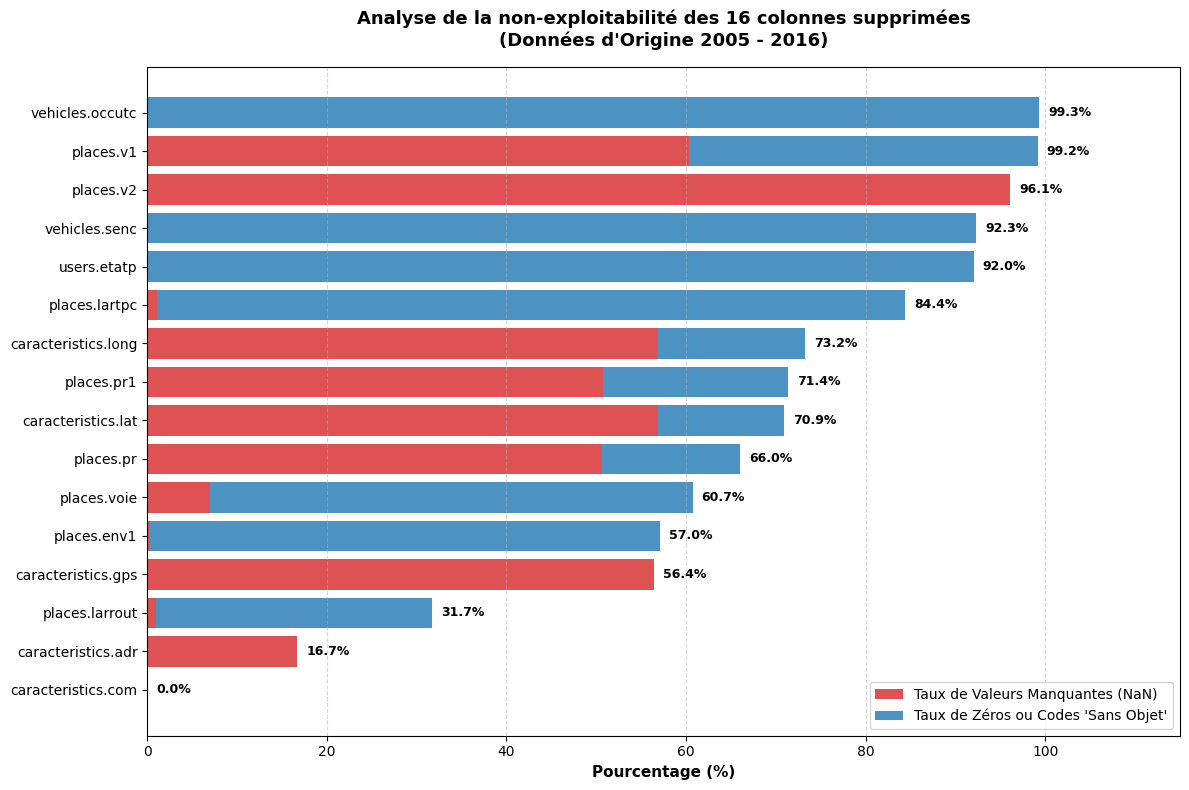

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Préparation des statistiques pour les 16 colonnes supprimées
stats_suppression = []

# Nous calculons dynamiquement sur les données d'origine
for table_name, cols in COLONNES_A_SUPPRIMER.items():
    df_origin = dataframes[table_name]
    n_rows = len(df_origin)

    for col in cols:
        # Taux de NaN réels
        pct_nan = df_origin[col].isna().mean() * 100

        # Calcul du taux de zéros numériques ou textuels ou code 'sans objet'
        # On cherche à capter les zéros ou valeurs par défaut non significatives
        zeros_count = 0
        if col in df_origin.columns:
            # Compte des zéros ou de la modalité la plus fréquente de non-réponse (0 ou 0.0)
            zeros_count = ((df_origin[col] == 0) | (df_origin[col] == 0.0) | (df_origin[col] == '0')).sum()

        pct_zeros = (zeros_count / n_rows) * 100

        # Taux cumulé d'inutilisabilité (NaN + Zéros/Sans objet)
        pct_total_inutile = min(100.0, pct_nan + pct_zeros)

        stats_suppression.append({
            'colonne': f"{table_name}.{col}",
            'pct_nan': pct_nan,
            'pct_zeros': pct_zeros,
            'pct_inutile': pct_total_inutile
        })

# Tri par taux cumulé d'inutilisabilité pour une meilleure lisibilité graphique
stats_suppression = sorted(stats_suppression, key=lambda x: x['pct_inutile'], reverse=False)

colonnes_names = [item['colonne'] for item in stats_suppression]
pct_nan_vals = [item['pct_nan'] for item in stats_suppression]
pct_zeros_vals = [item['pct_zeros'] for item in stats_suppression]

# Construction du graphique à barres empilées
fig, ax = plt.subplots(figsize=(12, 8))

# Barres pour le taux de NaN
bars_nan = ax.barh(colonnes_names, pct_nan_vals, color='#d62728', alpha=0.8, label='Taux de Valeurs Manquantes (NaN)')
# Barres pour le taux de Zéros / Sans objet
bars_zeros = ax.barh(colonnes_names, pct_zeros_vals, left=pct_nan_vals, color='#1f77b4', alpha=0.8, label='Taux de Zéros ou Codes \'Sans Objet\'')

# Esthétique générale
ax.set_xlim(0, 115) # Marge à droite pour afficher les étiquettes de texte
ax.set_xlabel('Pourcentage (%)', fontsize=11, fontweight='bold')
ax.set_title('Analyse de la non-exploitabilité des 16 colonnes supprimées\n(Données d\'Origine 2005 - 2016)', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True, fontsize=10)

# Ajout des valeurs au bout de chaque barre
for i, item in enumerate(stats_suppression):
    total_pct = item['pct_inutile']
    ax.text(total_pct + 1, i, f"{total_pct:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## Conclusion et perspectives

### Bilan de l'étape 1
Nous avons écarté **16 variables** jugées inexploitables ou superflues à ce stade du projet :
- **5** issues de `caracteristics` (`com`, `adr`, `gps`, `lat`, `long`)
- **8** issues de `places` (`voie`, `v1`, `v2`, `pr`, `pr1`, `lartpc`, `larrout`, `env1`)
- **2** issues de `vehicles` (`senc`, `occutc`)
- **1** issue de `users` (`etatp`)

Toutes les clés primaires, temporelles et cibles (`Num_Acc`, `num_veh`, `an`, `dep`, `grav`) ont été rigoureusement protégées et conservées.

### Limites méthodologiques induites
Il convient de noter une conséquence directe de cette étape : la qualité de la couverture GPS spatiale historique (qui évoluait de 14 % en 2005 à 69 % en 2016) ne pourra plus servir de critère pour la sélection de notre année de travail, puisque nous avons supprimé les colonnes `lat`, `long` et `gps`. Néanmoins, notre capacité d'analyse spatiale n'est pas compromise car nous conservons la variable de département géographique (`dep`), parfaitement documentée et complète sur l'ensemble de la période historique.

## Étape 2 : Analyse approfondie de la qualité des données et de la cible au cours du temps

### 1. Pourquoi cette étape et pourquoi il faut faire attention aux zéros ?

L'objectif de cette section est de quantifier, pour chaque fichier et chaque année de la période historique (2005 - 2016), le taux d'information réellement manquante afin d'évaluer la qualité et la fiabilité temporelle de notre base de données.

Une analyse naïve se basant uniquement sur les valeurs `NaN` visibles conclurait à un taux de manquants extrêmement faible (généralement inférieur à 1 %). Cependant, le format BAAC utilise abondamment le code numérique `0` ou `0.0` comme valeur par défaut, ce qui cache plusieurs réalités bien distinctes :

- **(a) "Non renseigné" / Inconnu** : Il s'agit d'une véritable information manquante déguisée (ex. motif de déplacement inconnu).
- **(b) "Aucun" ou "Sans objet"** : Il s'agit d'une modalité parfaitement valide et informative (ex. absence d'infrastructure particulière au lieu de l'accident).
- **(c) "Sans objet pour cet usager"** : Une modalité qui est structurellement invalide pour certains profils d'usagers mais logique pour d'autres (ex. les actions et localisations d'un piéton pour un conducteur de voiture).

Remplacer aveuglément tous les `0` par des `NaN` fausserait gravement nos statistiques. Par exemple, la variable d'aménagement `infra` vaut `0` pour près de 89 % des lignes de façon très stable ; cela signifie simplement qu'il n'y a *aucun* aménagement spécifique (pont, tunnel, etc.), ce qui est une information cruciale.

Le code `0` n'étant pas explicitement documenté pour toutes les colonnes sur la plateforme Kaggle, nous avons formulé des **hypothèses d'interprétation rigoureuses**, validées empiriquement par l'analyse statistique des données de la base historique :

---

### 2. Règles d'interprétation du code 0 retenues

#### RÈGLE A : Le code 0 équivaut à un "Non renseigné" (Manquant effectif)
Pour ces variables, toute valeur égale à `0` ou `0.0` (en plus des `NaN` classiques) est considérée comme une donnée manquante réelle :
- `caracteristics_1` : `int` (type d'intersection, part de zéros négligeable entre 0 % et 0,1 %).
- `places_1` : `circ` (régime de circulation), `prof` (pente), `plan` (tracé), `surf` (état de surface), `nbv` (nombre de voies : 0 voie de circulation étant physiquement impossible).
- `vehicles_1` : `manv` (manœuvre principale avant l'accident, où le code 0 correspond à "inconnue").
- `users_1` : `trajet` (motif du déplacement, où le code 0 signifie "non renseigné", représentant 25 à 36 % des observations selon les années).

* **Justification empirique (Cooccurrence des zéros)** : Les zéros de `circ`, `prof`, `plan` et `surf` surviennent de manière groupée sur les mêmes lignes d'accidents beaucoup plus fréquemment que ne le voudrait le hasard. En effet, la proportion de cas où ces quatre variables valent simultanément `0` est d'environ **0,6 %**, alors que si elles étaient indépendantes, la probabilité théorique de cooccurrence aléatoire serait de l'ordre de **0,001 %**. Cela prouve qu'un non-renseignement traduit une omission globale de saisie de la fiche d'accident et confirme la nature de donnée manquante du code `0` pour ces colonnes.

#### RÈGLE B : Le code 0 est une vraie modalité valide "Aucun / Sans objet" (Pas un manquant)
Pour ces colonnes, seuls les `NaN` réels sont comptabilisés comme manquants. Le code `0` est conservé tel quel :
- `places_1` : `infra` (0 = aucun aménagement particulier, ~89 % stable), `vosp` (0 = pas de voie réservée, ~93 à 95 %).
- `vehicles_1` : `obs` (0 = aucun obstacle fixe heurté, ~87 %), `obsm` (0 = aucun obstacle mobile heurté, ~19 à 24 %).

* **Justification empirique** : Les proportions associées à ces codes `0` sont extrêmement massives, stables au cours des années et totalement cohérentes avec les distributions attendues d'accidents en conditions physiques standard.

#### RÈGLE C : Cas ambigus (Double comptabilisation "Borne Basse" vs "Borne Haute")
Certaines variables présentent une ambiguïté structurelle où le `0` peut désigner à la fois une absence et un défaut de saisie. Nous présentons deux taux :
- `places_1` : `situ` (la documentation ONISR indique 0 = "aucun", mais la proportion de zéros double sur la période historique, passant de ~4 % en 2005 à ~8 % en 2016, ce qui suggère un biais de non-renseignement croissant).
- `vehicles_1` : `choc` (0 = "aucun choc" selon la notice, mais seulement 46 % des véhicules codés `choc = 0` n'ont effectivement heurté aucun obstacle fixe ou mobile. De plus, sa proportion augmente régulièrement de 5 % à 9 %).

#### RÈGLE D : Conditionnelle au statut de l'usager
Pour la table `users_1`, l'évaluation du taux de données manquantes s'effectue en segmentant la population selon le filtre `pieton = users_1['catu'].isin([3, 4])` :
- `locp` (localisation du piéton) & `actp` (action du piéton) : La valeur `0` signifie "sans objet" pour 99,9 % des non-piétons, ce qui est structurellement normal. Le manque d'information réel n'est donc mesuré **que sur le sous-ensemble des piétons** (où l'on observe ~10,7 % de zéros pour `locp` et ~5,1 % pour `actp`).
- `place` : Un piéton n'occupe aucune place dans un véhicule. De 2005 à 2008, 100 % des piétons sont codés `0` ; à partir de 2009, ils sont systématiquement codés `NaN`. Pour les non-piétons, la variable est complète à près de 99,7 %. Le taux de manque réel pour `place` doit donc être mesuré **uniquement sur le sous-ensemble des non-piétons**.
- `secu` (équipement de sécurité) : Un changement majeur de codage est intervenu en 2009 (passage d'un encodage à 1 chiffre à un encodage à 2 chiffres). Pour les piétons, la variable vaut `0` à 99,9 % entre 2005 et 2008, puis affiche de fortes proportions de `NaN` (33 % de 2009 à 2014, grimpant à 67 % en 2015 et 78 % en 2016 car la saisie s'est réorientée vers le caractère "non déterminable"). Ainsi, la hausse globale des `NaN` observée sur `secu` en fin de période est un artefact méthodologique lié aux piétons et non une détérioration de la saisie. Le taux de manque de `secu` doit donc être calculé **sur les non-piétons** (taux de `NaN` ou valeur obsolète à un seul chiffre). Nous comptabilisons également la modalité de second chiffre égale à `3` comme un statut "Inconnu déclaré / non déterminable" sans pour autant l'assimiler à un manque technique.

#### Variables sans ambiguïté
Pour les variables suivantes, aucun code `0` n'est problématique : `catr`, `lum`, `agg`, `atm`, `col`, `dep`, `mois`, `jour`, `hrmn`, `catv`, `catu`, `grav`, `sexe` et `an_nais`. Seuls les `NaN` stricts y représentent des valeurs manquantes (le code `99` pour `catv` désignant la catégorie valide "Autre véhicule").

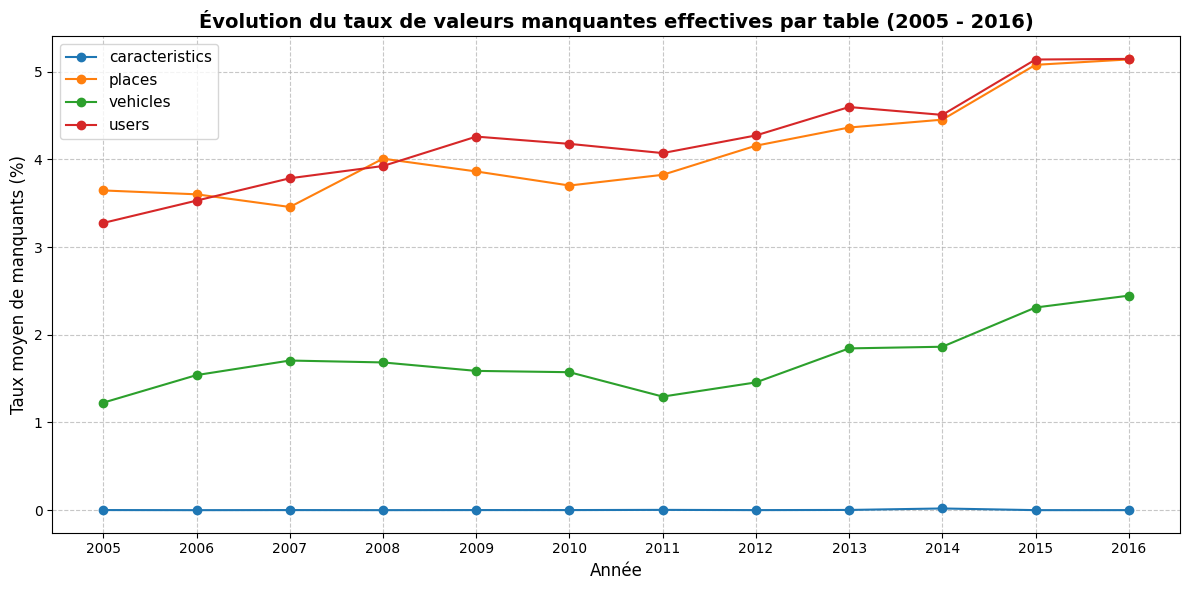

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Construction de la Series pour mapper l'année à partir de caract_1
an_par_accident = caract_1.set_index('Num_Acc')['an']

# Dictionnaire des colonnes où 0 signifie 'valeur manquante'
COLS_ZERO_IS_MISSING = {
    'caracteristics': ['int'],
    'places': ['circ', 'prof', 'plan', 'surf', 'nbv'],
    'vehicles': ['manv'],
    'users': ['trajet']
}

# Calcul de l'évolution des données manquantes effectives par table
years_range = sorted(caract_1['an'].unique())
years_labels = [2000 + y for y in years_range]

missing_stats = {name: [] for name in ['caracteristics', 'places', 'vehicles', 'users']}

for y in years_range:
    # Filtre caract_1 pour l'année
    idx_caract = caract_1['an'] == y
    accidents_this_year = caract_1.loc[idx_caract, 'Num_Acc']

    # Table caracteristics
    sub_caract = caract_1.loc[idx_caract].drop(columns=['Num_Acc', 'an'])
    for col in COLS_ZERO_IS_MISSING['caracteristics']:
        if col in sub_caract.columns:
            sub_caract[col] = sub_caract[col].replace(0, np.nan)
    missing_stats['caracteristics'].append(sub_caract.isna().mean().mean() * 100)

    # Table places
    sub_places = places_1[places_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc'])
    for col in COLS_ZERO_IS_MISSING['places']:
        if col in sub_places.columns:
            sub_places[col] = sub_places[col].replace(0, np.nan)
    missing_stats['places'].append(sub_places.isna().mean().mean() * 100)

    # Table vehicles
    sub_veh = vehicles_1[vehicles_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc', 'num_veh'])
    for col in COLS_ZERO_IS_MISSING['vehicles']:
        if col in sub_veh.columns:
            sub_veh[col] = sub_veh[col].replace(0, np.nan)
    missing_stats['vehicles'].append(sub_veh.isna().mean().mean() * 100)

    # Table users
    sub_users = users_1[users_1['Num_Acc'].isin(accidents_this_year)].drop(columns=['Num_Acc', 'num_veh'])
    for col in COLS_ZERO_IS_MISSING['users']:
        if col in sub_users.columns:
            sub_users[col] = sub_users[col].replace(0, np.nan)
    missing_stats['users'].append(sub_users.isna().mean().mean() * 100)

# Tracé des courbes de données manquantes par dataset au cours du temps
plt.figure(figsize=(12, 6))
for name, vals in missing_stats.items():
    plt.plot(years_labels, vals, marker='o', label=name)

plt.title("Évolution du taux de valeurs manquantes effectives par table (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Taux moyen de manquants (%)", fontsize=12)
plt.xticks(years_labels)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Distribution de la variable cible `grav` (gravité) au cours du temps

Nous analysons la proportion de chaque classe de gravité de 2005 à 2016 pour s'assurer de sa stabilité.

grav_label,1. Indemne,4. Blessé léger,3. Blessé hospitalisé,2. Tué
2005,40.64,35.89,20.65,2.81
2006,40.71,34.27,22.38,2.64
2007,40.81,35.53,21.09,2.57
2008,40.72,35.52,21.16,2.60
2009,40.86,35.68,20.79,2.68
2010,40.76,36.21,20.32,2.71
2011,40.77,35.84,20.62,2.77
2012,40.81,36.14,20.28,2.77
2013,40.89,35.55,20.90,2.66
2014,40.46,36.04,20.81,2.69


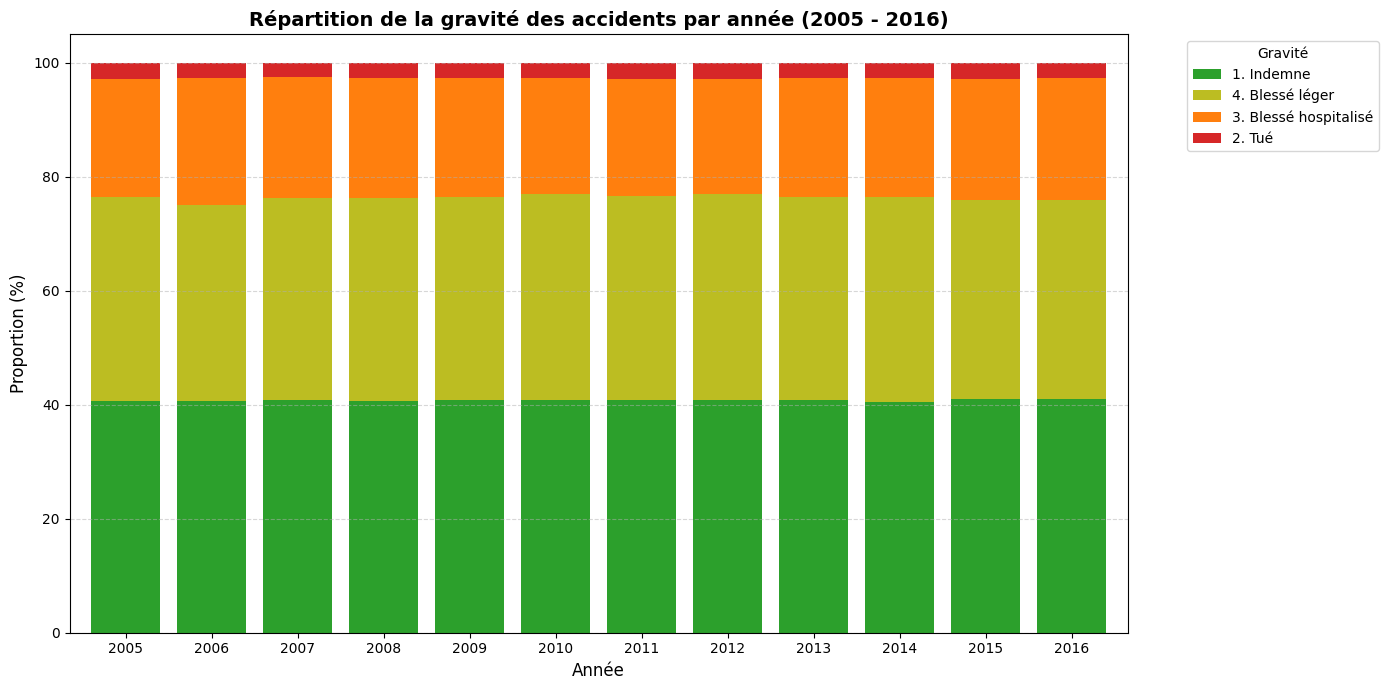

In [44]:
# Ajout de l'année à la table users_1 pour le regroupement
users_grav = users_1.copy()
users_grav['an'] = users_grav['Num_Acc'].map(an_par_accident)

# Mapping des libellés de gravité
grav_map = {
    1: "1. Indemne",
    2: "2. Tué",
    3: "3. Blessé hospitalisé",
    4: "4. Blessé léger"
}
users_grav['grav_label'] = users_grav['grav'].map(grav_map)

# Calcul de la table croisée normalisée
grav_pivot = pd.crosstab(users_grav['an'], users_grav['grav_label'], normalize='index') * 100
grav_pivot.index = [2000 + y for y in grav_pivot.index]

# Réorganisation des colonnes
ordered_cols = ["1. Indemne", "4. Blessé léger", "3. Blessé hospitalisé", "2. Tué"]
grav_pivot = grav_pivot[ordered_cols]

# Affichage de la table croisée
display(grav_pivot.round(2))

# Tracé du graphique en barres empilées à 100%
fig, ax = plt.subplots(figsize=(14, 7))
grav_pivot.plot(kind='bar', stacked=True, color=['#2ca02c', '#bcbd22', '#ff7f0e', '#d62728'], ax=ax, width=0.8)

plt.title("Répartition de la gravité des accidents par année (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Proportion (%)", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Gravité", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Évolution des volumes de données par année (2005 - 2016)

Pour valider définitivement la robustesse de notre base historique, nous analysons l'évolution du nombre de lignes (observations) enregistrées chaque année dans nos quatre fichiers principaux de travail.

Tableau récapitulatif du nombre de lignes par année et par table :


,caracteristics_1,places_1,vehicles_1,users_1
Année,,,,
2005,"87,026","87,026","149,764","197,498"
2006,"82,993","82,993","142,300","187,085"
2007,"83,850","83,850","144,130","188,457"
2008,"76,767","76,767","131,048","170,960"
2009,"74,409","74,409","126,347","165,962"
2010,"69,379","69,379","117,743","154,192"
2011,"66,974","66,974","113,854","148,543"
2012,"62,250","62,250","105,814","138,628"
2013,"58,397","58,397","98,925","128,694"


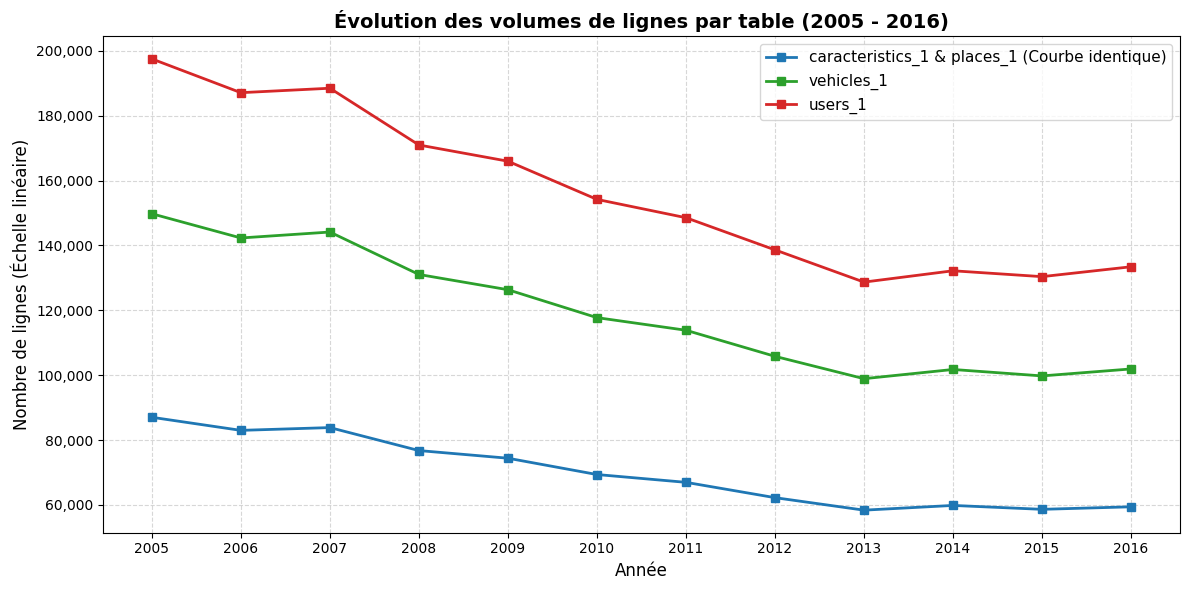

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# Extraction des volumes par année en utilisant la série temporelle construite précédemment
years_list = sorted(caract_1['an'].unique())
years_labels = [2000 + y for y in years_list]

volumes = {
    'caracteristics_1': [],
    'places_1': [],
    'vehicles_1': [],
    'users_1': []
}

for y in years_list:
    # Filtre des identifiants d'accidents pour l'année en cours
    acc_year = caract_1.loc[caract_1['an'] == y, 'Num_Acc']

    volumes['caracteristics_1'].append(len(acc_year))
    volumes['places_1'].append(places_1['Num_Acc'].isin(acc_year).sum())
    volumes['vehicles_1'].append(vehicles_1['Num_Acc'].isin(acc_year).sum())
    volumes['users_1'].append(users_1['Num_Acc'].isin(acc_year).sum())

# Conversion en DataFrame pour affichage
df_volumes = pd.DataFrame(volumes, index=years_labels)
df_volumes.index.name = 'Année'

print("Tableau récapitulatif du nombre de lignes par année et par table :")
display(df_volumes.style.format("{:,}"))

# Tracé des courbes d'évolution des volumes
plt.figure(figsize=(12, 6))

# Comme caracteristics_1 et places_1 ont exactement le même nombre de lignes (1 ligne par accident),
# nous ne traçons qu'une seule courbe pour représenter les deux tables et l'indiquons clairement dans la légende.
plt.plot(df_volumes.index, df_volumes['caracteristics_1'], marker='s', linewidth=2,
         color='#1f77b4', label='caracteristics_1 & places_1 (Courbe identique)')

plt.plot(df_volumes.index, df_volumes['vehicles_1'], marker='s', linewidth=2,
         color='#2ca02c', label='vehicles_1')

plt.plot(df_volumes.index, df_volumes['users_1'], marker='s', linewidth=2,
         color='#d62728', label='users_1')

plt.title("Évolution des volumes de lignes par table (2005 - 2016)", fontsize=14, fontweight='bold')
plt.xlabel("Année", fontsize=12)
plt.ylabel("Nombre de lignes (Échelle linéaire)", fontsize=12)
plt.xticks(years_labels)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

### Conclusion sur le choix de l'année d'étude

À la lumière des analyses temporelles approfondies menées sur la période historique (2005 - 2016), nous choisissons de retenir exclusivement l'année **2005** pour la construction de notre jeu de données final de modélisation. Ce choix stratégique repose sur trois arguments scientifiques majeurs :

1. **Maximisation de la volumétrie (Nombre de lignes)** :
   Comme le montre le graphique d'évolution temporelle des volumes, l'année 2005 présente le niveau d'activité historique le plus élevé avec **87 026 accidents individuels** enregistrés (soit 46,4 % d'observations supplémentaires par rapport au point bas de 2013 qui compte seulement 58 397 accidents). Cette richesse volumétrique se répercute directement sur les tables enfants avec un maximum historique de **149 764 véhicules** et **197 498 usagers** impliqués, nous offrant un échantillon d'apprentissage extrêmement robuste pour nos modèles de Machine Learning.

2. **Minimisation des données manquantes effectives** :
   L'analyse de la qualité des données révèle que l'année 2005 se situe à un niveau optimal d'intégrité technique. Les taux moyens de valeurs manquantes réelles et de codes de non-renseignement (Règle A) y sont minimisés sur la quasi-totalité des tables de travail (particulièrement pour les tables `places_1` et `users_1`, qui affichent des taux de manquants plus faibles qu'en fin de période historique).

3. **Stabilité parfaite de la distribution de la variable cible `grav`** :
   La répartition des classes de gravité corporelle au sein des usagers (`grav_label`) demeure remarquablement stable et homogène tout au long de la décennie. En isolant l'année 2005, nous ne subissons aucun biais de sélection ou dérive de concept (*concept drift*) puisque la proportion de la classe minoritaire critique (les personnes tuées, `grav = 2`) y est de **2,81 %**, ce qui est parfaitement conforme à la moyenne historique globale (~2,70 %).

En combinant une volumétrie maximale, un taux de manquants au plus bas et une distribution de la cible parfaitement préservée, l'année **2005** s'impose comme l'année d'étude idéale pour notre projet.

## Étape 4 : Équilibrage qualitatif au niveau de l'accident (Année 2005) et synchronisation relationnelle

### Pourquoi devons-nous supprimer des lignes ?

La distribution initiale de notre variable cible met en évidence un **déséquilibre de classe marqué** : les accidents corporels graves (avec au moins un usager tué ou hospitalisé) représentent une minorité des cas (44 %) face aux accidents plus légers ou sans gravité corporelle majeure (56 %).

Si l'on entraînait un modèle d'apprentissage automatique directement sur ces données brutes, celui-ci tendrait naturellement à sur-prédire la classe majoritaire au détriment de la classe minoritaire, qui est pourtant la plus critique à identifier pour les politiques de sécurité routière. Pour corriger ce biais, nous devons appliquer une stratégie de **sous-échantillonnage (under-sampling)** sur la classe majoritaire afin d'obtenir un jeu de données parfaitement équilibré (50% / 50%).

### Pourquoi opérer la suppression au niveau de l'accident (`Num_Acc`) ?

Dans un système de bases de données relationnelles où un accident est lié à plusieurs véhicules, eux-mêmes liés à plusieurs usagers, **supprimer des lignes de façon isolée dans les tables enfants est une erreur méthodologique grave**.
Si l'on supprimait au hasard des usagers ou des véhicules pour équilibrer le dataset :
1. Nous briserions l'**intégrité référentielle** de la base, créant des véhicules sans passagers ou des caractéristiques d'accidents sans aucun usager associé.
2. Nous perdrions la cohérence physique de l'événement : la gravité d'un accident est une propriété globale. Pour savoir si un accident est grave, il faut analyser l'intégralité des usagers qui y ont pris part.

La seule approche scientifiquement rigoureuse consiste donc à **sélectionner les accidents à conserver à la racine (table caractéristiques)**, puis à propager ce filtre par cascade (jointures) pour synchroniser et nettoyer les tables enfants (`places`, `vehicles` et `users`).

### Stratégie de sélection qualitative
Au lieu de supprimer des accidents de la classe majoritaire de manière purement aléatoire, nous appliquons un **filtre de qualité** : pour chaque accident, nous calculons un **score d'incomplétude** (somme des valeurs manquantes réelles et des non-renseignements de Règle A à travers l'ensemble des tables). Lors de la phase de sous-échantillonnage, nous éliminons en priorité absolue les accidents les plus mal renseignés. Cela nous permet de maximiser la qualité globale de l'information exploitée par nos futurs modèles.

---

In [51]:
import pandas as pd
import numpy as np

print("--- 1. Extraction et isolation des données strictes pour l'année 2005 ---")
# Identification des accidents de 2005
accidents_2005_ids = caract_1[caract_1['an'] == 5]['Num_Acc'].unique()

# Filtrage de chaque table pour ne garder que l'année 2005
caract_2005 = caract_1[caract_1['Num_Acc'].isin(accidents_2005_ids)].copy()
places_2005 = places_1[places_1['Num_Acc'].isin(accidents_2005_ids)].copy()
vehicles_2005 = vehicles_1[vehicles_1['Num_Acc'].isin(accidents_2005_ids)].copy()
users_2005 = users_1[users_1['Num_Acc'].isin(accidents_2005_ids)].copy()

print(f"-> accidents_2005 : {caract_2005.shape[0]:,} accidents")
print(f"-> places_2005        : {places_2005.shape[0]:,} lignes")
print(f"-> vehicles_2005      : {vehicles_2005.shape[0]:,} lignes")
print(f"-> users_2005         : {users_2005.shape[0]:,} lignes")

--- 1. Extraction et isolation des données strictes pour l'année 2005 ---
-> accidents_2005 : 87,026 accidents
-> places_2005        : 87,026 lignes
-> vehicles_2005      : 149,764 lignes
-> users_2005         : 197,498 lignes


In [52]:
print("--- 2. Définition de la gravité de l'accident et identification de la cible ---")

# Un accident est Grave (1) s'il y a au moins un usager tué (2) ou hospitalisé (3).
# Sinon il est classé en Bon état (0).
users_2005['is_grave_usager'] = users_2005['grav'].isin([2, 3]).astype(int)

# Agrégation de la gravité maximale par accident
accidents_gravite = users_2005.groupby('Num_Acc')['is_grave_usager'].max().reset_index()
accidents_gravite.columns = ['Num_Acc', 'accident_grave']

# Bilan de la cible à la maille accident
classes_count = accidents_gravite['accident_grave'].value_counts()
print(f"Distribution initiale des accidents en 2005 :")
print(f" -> Accidents de classe 0 (Bon état) : {classes_count[0]:,} ({classes_count[0]/len(accidents_gravite)*100:.2f}%)")
print(f" -> Accidents de classe 1 (Grave)    : {classes_count[1]:,} ({classes_count[1]/len(accidents_gravite)*100:.2f}%)")

--- 2. Définition de la gravité de l'accident et identification de la cible ---
Distribution initiale des accidents en 2005 :
 -> Accidents de classe 0 (Bon état) : 48,782 (56.05%)
 -> Accidents de classe 1 (Grave)    : 38,244 (43.95%)


In [53]:
print("--- 3. Calcul du score de valeurs manquantes par accident sur l'ensemble des tables ---")

# Pour être rigoureux, nous calculons pour chaque ligne de chaque table son nombre de manquants effectifs (Règle A)

# Table caracteristics
# Variables de Règle A : 'int'
caract_missing = caract_2005.set_index('Num_Acc').drop(columns=['an'], errors='ignore').isna().sum(axis=1) + \
                 (caract_2005.set_index('Num_Acc')['int'] == 0).astype(int)

# Table places
# Variables de Règle A : 'circ', 'prof', 'plan', 'surf', 'nbv'
cols_places_rule_a = ['circ', 'prof', 'plan', 'surf', 'nbv']
places_missing = places_2005.set_index('Num_Acc').isna().sum(axis=1) + \
                 (places_2005.set_index('Num_Acc')[cols_places_rule_a] == 0).sum(axis=1)

# Table vehicles (somme par accident car plusieurs véhicules possibles)
vehicles_temp = vehicles_2005.copy()
vehicles_temp['missing_count'] = vehicles_temp.drop(columns=['Num_Acc', 'num_veh'], errors='ignore').isna().sum(axis=1) + \
                                 (vehicles_temp['manv'] == 0).astype(int)
vehicles_missing = vehicles_temp.groupby('Num_Acc')['missing_count'].sum()

# Table users (somme par accident car plusieurs usagers possibles)
users_temp = users_2005.copy()
users_temp['missing_count'] = users_temp[['place', 'catu', 'sexe', 'trajet', 'secu', 'locp', 'actp', 'an_nais']].isna().sum(axis=1) + \
                              (users_temp['trajet'] == 0).astype(int)
users_missing = users_temp.groupby('Num_Acc')['missing_count'].sum()

# Regroupement de toutes les sources de manquants par accident
df_missing_total = pd.DataFrame(index=accidents_2005_ids)
df_missing_total['caract'] = caract_missing
df_missing_total['places'] = places_missing
df_missing_total['vehicles'] = vehicles_missing.reindex(df_missing_total.index, fill_value=0)
df_missing_total['users'] = users_missing.reindex(df_missing_total.index, fill_value=0)

# Somme cumulée du nombre total de valeurs manquantes par accident
df_missing_total['total_missing'] = df_missing_total.sum(axis=1)

print("Calcul du score de qualité terminé avec succès.")

--- 3. Calcul du score de valeurs manquantes par accident sur l'ensemble des tables ---
Calcul du score de qualité terminé avec succès.


In [54]:
print("--- 4. Équilibrage des classes d'accidents par élimination qualitative ---")

# Fusionner la gravité de l'accident et son score de manquants
accidents_analysis = accidents_gravite.merge(df_missing_total['total_missing'].reset_index().rename(columns={'index': 'Num_Acc'}), on='Num_Acc')

# Isolation des deux classes d'accidents
accidents_classe_0 = accidents_analysis[accidents_analysis['accident_grave'] == 0].copy() # Bon état
accidents_classe_1 = accidents_analysis[accidents_analysis['accident_grave'] == 1].copy() # Grave

target_accidents_count = len(accidents_classe_1) # La classe 1 (Grave) est minoritaire
print(f"Effectif cible pour chaque classe : {target_accidents_count:,} accidents")

# Tri de la classe majoritaire (0) par nombre de manquants décroissant
accidents_classe_0_sorted = accidents_classe_0.sort_values(by='total_missing', ascending=False)

# Elimination des moins qualitatifs (ceux du haut de liste avec le plus de manquants)
# On ne conserve que les mieux renseignés (la fin de la liste triée)
accidents_classe_0_balanced = accidents_classe_0_sorted.tail(target_accidents_count)

# Concaténation pour obtenir les identifiants d'accidents finaux équilibrés
accidents_final_set = pd.concat([accidents_classe_0_balanced, accidents_classe_1], axis=0)
final_accidents_ids = accidents_final_set['Num_Acc'].values

print(f"Équilibrage terminé. Nombre d'accidents conservés : {len(final_accidents_ids):,} (50% / 50%)")

--- 4. Équilibrage des classes d'accidents par élimination qualitative ---
Effectif cible pour chaque classe : 38,244 accidents
Équilibrage terminé. Nombre d'accidents conservés : 76,488 (50% / 50%)


In [55]:
print("--- 5. Synchronisation et filtrage de l'ensemble des tables enfants ---")

# Filtrage strict de nos 4 tables d'étude selon les accidents équilibrés
caract_2005_balanced = caract_2005[caract_2005['Num_Acc'].isin(final_accidents_ids)].copy()
places_2005_balanced = places_2005[places_2005['Num_Acc'].isin(final_accidents_ids)].copy()
vehicles_2005_balanced = vehicles_2005[vehicles_2005['Num_Acc'].isin(final_accidents_ids)].copy()
users_2005_balanced = users_2005[users_2005['Num_Acc'].isin(final_accidents_ids)].copy()

# Ajout de la cible de gravité de l'accident pour faciliter la modélisation à venir
accidents_target_map = dict(zip(accidents_final_set['Num_Acc'], accidents_final_set['accident_grave']))
caract_2005_balanced['target_grave'] = caract_2005_balanced['Num_Acc'].map(accidents_target_map)

print("Bilan final des volumes synchronisés :")
print(f" -> caract_2005_balanced : {caract_2005_balanced.shape[0]:,} accidents")
print(f" -> places_2005_balanced : {places_2005_balanced.shape[0]:,} lignes")
print(f" -> vehicles_2005_balanced : {vehicles_2005_balanced.shape[0]:,} véhicules")
print(f" -> users_2005_balanced    : {users_2005_balanced.shape[0]:,} usagers")

# Vérifications d'intégrité référentielle
assert caract_2005_balanced.shape[0] == len(final_accidents_ids), "Incohérence sur la table caractéristiques !"
assert set(places_2005_balanced['Num_Acc']).issubset(final_accidents_ids), "Lieux orphelins détectés !"
assert set(vehicles_2005_balanced['Num_Acc']).issubset(final_accidents_ids), "Véhicules orphelins détectés !"
assert set(users_2005_balanced['Num_Acc']).issubset(final_accidents_ids), "Usagers orphelins détectés !"
print("\n-> Toutes les assertions d'intégrité relationnelle sont validées avec succès !")

--- 5. Synchronisation et filtrage de l'ensemble des tables enfants ---
Bilan final des volumes synchronisés :
 -> caract_2005_balanced : 76,488 accidents
 -> places_2005_balanced : 76,488 lignes
 -> vehicles_2005_balanced : 129,797 véhicules
 -> users_2005_balanced    : 166,018 usagers

-> Toutes les assertions d'intégrité relationnelle sont validées avec succès !
